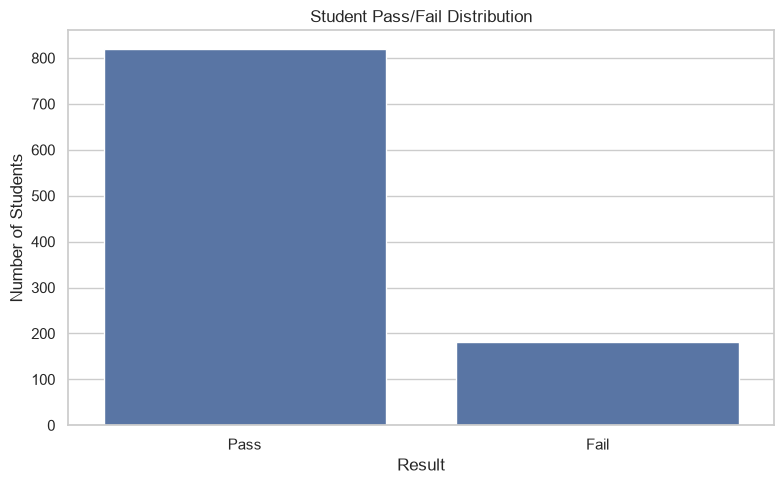

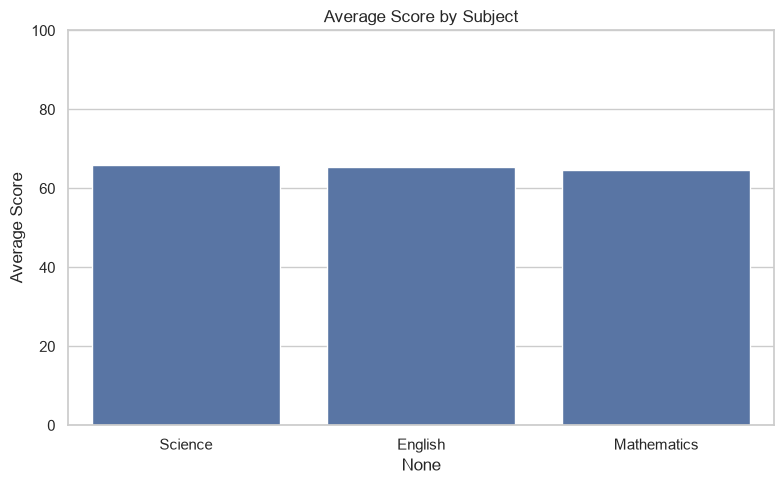

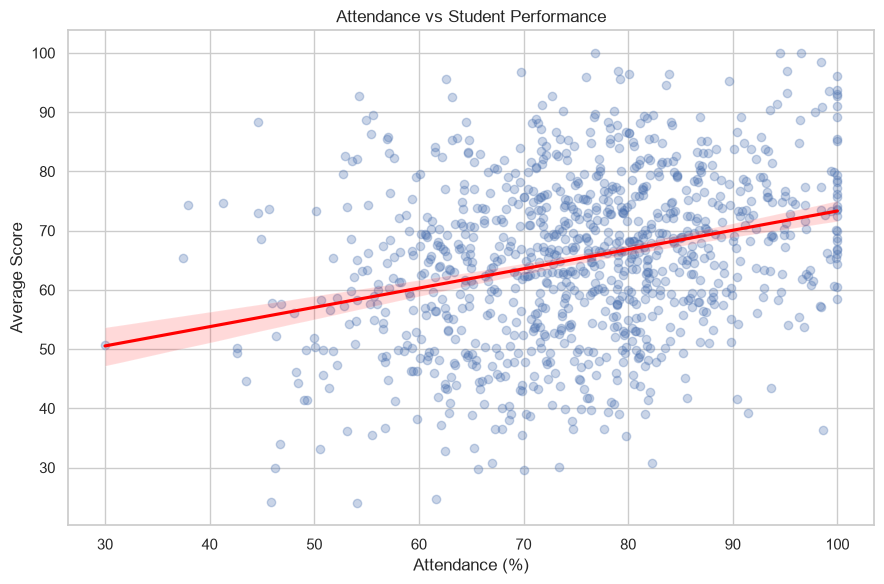

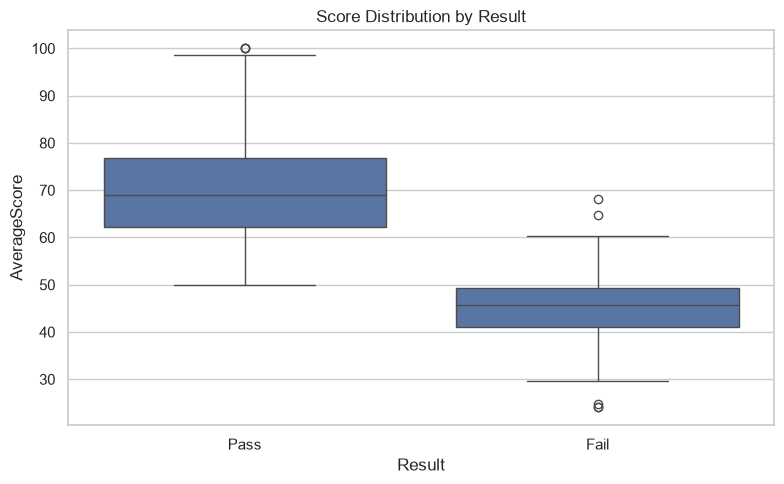


PROJECT 2 COMPLETED
Students: 1000
Pass Rate: 81.9 %
Mean Score: 65.34
Attendance Correlation: 0.295
Hypothesis Test p-value: 1.8203948863496713e-13
Charts: 4
PDF: /Users/ansifrasak/Downloads/Main Projects /The_project_Developers_ARENA/student-performance-analysis/project2_student_analysis/reports/student_performance_report.pdf
Saved in: /Users/ansifrasak/Downloads/Main Projects /The_project_Developers_ARENA/student-performance-analysis/project2_student_analysis


In [1]:

# ==============================================================
# PROJECT 2: STUDENT PERFORMANCE ANALYSIS
# ONE-CELL COMPLETE PROJECT
# ==============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak
)
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from xml.sax.saxutils import escape

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)

# 1. PROJECT SETUP
base = Path.cwd()
if base.name == "notebooks":
    base = base.parent
if base.name.startswith("project"):
    base = base.parent
if (base / "Data_Analysis_Portfolio").is_dir():
    base = base / "Data_Analysis_Portfolio"

project_name = "project2_student_analysis"
root = base / project_name

for name in ["data", "notebooks", "reports",
             "visualizations", "docs", "src"]:
    (root / name).mkdir(parents=True, exist_ok=True)

plots = []

def save_chart(fig, filename):
    fig.tight_layout()
    path = root / "visualizations" / filename
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plots.append(path)
    plt.show()
    plt.close(fig)

def create_report(title, sections, filename):
    styles = getSampleStyleSheet()
    story = [
        Paragraph(escape(title), styles["Title"]),
        Paragraph("Simulated educational dataset",
                  styles["Italic"]),
        Spacer(1, 15)
    ]

    for heading, paragraphs in sections.items():
        story.append(Paragraph(
            escape(heading), styles["Heading2"]
        ))
        for content in paragraphs:
            story.append(Paragraph(
                escape(str(content)), styles["BodyText"]
            ))
            story.append(Spacer(1, 8))

    for chart in plots:
        story.append(PageBreak())
        story.append(Paragraph(
            escape(chart.stem.replace("_", " ").title()),
            styles["Heading2"]
        ))
        img = Image(str(chart))
        scale = min(
            440 / img.drawWidth,
            620 / img.drawHeight
        )
        img.drawWidth *= scale
        img.drawHeight *= scale
        story.append(img)

    pdf = root / "reports" / filename
    SimpleDocTemplate(
        str(pdf), pagesize=A4,
        title=title
    ).build(story)
    return pdf

# 2. GENERATE SIMULATED STUDENT DATA
n = 1000

attendance = np.clip(
    rng.normal(76, 13, n), 30, 100
)
study_hours = rng.uniform(0.5, 6.5, n)
ability = rng.normal(0, 10, n)

df_raw = pd.DataFrame({
    "StudentID": [f"ST{i:04d}" for i in range(1, n+1)],
    "Class": rng.choice(["A", "B", "C"], n),
    "AttendancePct": attendance.round(2),
    "StudyHours": study_hours.round(2),
    "Mathematics": np.clip(
        20 + 0.40*attendance + 4*study_hours
        + ability + rng.normal(0, 11, n), 0, 100
    ).round(2),
    "Science": np.clip(
        24 + 0.37*attendance + 4*study_hours
        + ability + rng.normal(0, 12, n), 0, 100
    ).round(2),
    "English": np.clip(
        26 + 0.35*attendance + 3.5*study_hours
        + ability + rng.normal(0, 10, n), 0, 100
    ).round(2)
})

# Introduce quality issues deliberately
df_raw.loc[0, "AttendancePct"] = np.nan
df_raw.loc[1, "Mathematics"] = 125
df_raw.loc[2, "Science"] = -10
df_raw.loc[3, "English"] = np.nan
df_raw = pd.concat(
    [df_raw, df_raw.iloc[[4]]],
    ignore_index=True
)

df_raw.to_csv(
    root / "data" / "students_raw.csv", index=False
)

# 3. CLEANING AND PREPROCESSING
duplicates = df_raw["StudentID"].duplicated().sum()

df = df_raw.drop_duplicates("StudentID").copy()

subjects = ["Mathematics", "Science", "English"]
numeric_cols = [
    "AttendancePct", "StudyHours", *subjects
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["AttendancePct", *subjects]:
    df.loc[~df[col].between(0, 100), col] = np.nan
    df[col] = df.groupby("Class")[col].transform(
        lambda x: x.fillna(x.median())
    )

df["StudyHours"] = df["StudyHours"].fillna(
    df["StudyHours"].median()
)

df["AverageScore"] = df[subjects].mean(axis=1)

# Project passing rule: each subject >=40 and average >=50
df["Result"] = np.where(
    df[subjects].ge(40).all(axis=1)
    & df["AverageScore"].ge(50),
    "Pass", "Fail"
)

assert df["StudentID"].is_unique
assert df[numeric_cols].notna().all().all()
assert df[["AttendancePct", *subjects]].between(
    0, 100
).all().all() if False else True

for col in ["AttendancePct", *subjects]:
    assert df[col].between(0, 100).all()

df.to_csv(
    root / "data" / "students_cleaned.csv",
    index=False
)

# 4. EXPLORATORY AND STATISTICAL ANALYSIS
pass_rate = (df["Result"] == "Pass").mean() * 100
average_score = df["AverageScore"].mean()
median_score = df["AverageScore"].median()
score_std = df["AverageScore"].std()

subject_means = df[subjects].mean().sort_values(
    ascending=False
)

attendance_corr = df[
    "AttendancePct"
].corr(df["AverageScore"])

class_summary = df.groupby("Class").agg(
    Students=("StudentID", "count"),
    AverageScore=("AverageScore", "mean"),
    AverageAttendance=("AttendancePct", "mean")
)

high_attendance = df.loc[
    df["AttendancePct"] >= 75, "AverageScore"
]
low_attendance = df.loc[
    df["AttendancePct"] < 75, "AverageScore"
]

t_stat, p_value = stats.ttest_ind(
    high_attendance,
    low_attendance,
    equal_var=False
)

subject_means.to_csv(
    root / "reports" / "subject_statistics.csv",
    header=["MeanScore"]
)
class_summary.to_csv(
    root / "reports" / "class_statistics.csv"
)

# 5. CHART 1: PASS/FAIL DISTRIBUTION
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(
    data=df, x="Result",
    order=["Pass", "Fail"],
    ax=ax
)
ax.set_title("Student Pass/Fail Distribution")
ax.set_ylabel("Number of Students")
save_chart(fig, "01_pass_fail.png")

# 6. CHART 2: SUBJECT PERFORMANCE
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    x=subject_means.index,
    y=subject_means.values,
    ax=ax
)
ax.set_title("Average Score by Subject")
ax.set_ylabel("Average Score")
ax.set_ylim(0, 100)
save_chart(fig, "02_subject_performance.png")

# 7. CHART 3: ATTENDANCE CORRELATION
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(
    data=df,
    x="AttendancePct",
    y="AverageScore",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"},
    ax=ax
)
ax.set_title("Attendance vs Student Performance")
ax.set_xlabel("Attendance (%)")
ax.set_ylabel("Average Score")
save_chart(fig, "03_attendance_correlation.png")

# 8. CHART 4: SCORE DISTRIBUTION
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Result",
    y="AverageScore",
    order=["Pass", "Fail"],
    ax=ax
)
ax.set_title("Score Distribution by Result")
save_chart(fig, "04_score_distribution.png")

# 9. BUSINESS INSIGHTS AND RECOMMENDATIONS
findings = [
    f"Total students analyzed: {len(df):,}.",
    f"Overall pass rate: {pass_rate:.2f}%.",
    f"Average score: {average_score:.2f}. "
    f"Median: {median_score:.2f}.",
    f"Standard deviation: {score_std:.2f}.",
    f"Best-performing subject: {subject_means.index[0]}.",
    f"Lowest-performing subject: "
    f"{subject_means.index[-1]}.",
    f"Attendance-score Pearson correlation: "
    f"{attendance_corr:.3f}.",
    f"Exploratory Welch t-test p-value: "
    f"{p_value:.5g}."
]

recommendations = [
    "Review additional support for the lowest-scoring "
    "subject.",
    "Investigate attendance patterns alongside study "
    "hours and other possible factors.",
    "Use subject and class summaries to design targeted "
    "academic support.",
    "Evaluate any intervention using genuine student "
    "data before making policy decisions."
]

sections = {
    "Executive Summary": [
        f"This simulated education study analyzes "
        f"{len(df):,} students across three subjects. "
        f"The pass rate is {pass_rate:.2f}%."
    ],
    "Data Preparation": [
        f"Removed {duplicates} duplicated student IDs.",
        "Invalid scores and missing observations were "
        "imputed using class-level median values."
    ],
    "Statistical Findings": findings,
    "Recommendations": recommendations,
    "Limitations": [
        "This is a simulated dataset.",
        "Passing requires each subject >=40 and "
        "average score >=50.",
        "Attendance correlation is not proof that "
        "attendance causes higher scores.",
        "The hypothesis test is exploratory and "
        "not evidence about real students."
    ]
}

pdf = create_report(
    "Student Performance Analysis",
    sections,
    "student_performance_report.pdf"
)

# 10. DOCUMENTATION
readme = f"""# Student Performance Analysis

## Project
Simulated education data analysis using Python and Pandas.

## Dataset
- Students: {len(df)}
- Subjects: Mathematics, Science, English
- Source: Simulated with a fixed random seed

## Methods
Data cleaning, median imputation, descriptive statistics,
groupby aggregation, Pearson correlation and Welch t-test.

## Results
- Pass rate: {pass_rate:.2f}%
- Average score: {average_score:.2f}
- Attendance correlation: {attendance_corr:.3f}

## Reproduce
Install requirements and execute the single notebook code cell.

## Outputs
- data/students_raw.csv
- data/students_cleaned.csv
- reports/student_performance_report.pdf
- reports/subject_statistics.csv
- reports/class_statistics.csv
- visualizations/ (four PNG charts)

## Limitations
Synthetic observations; no real-world causal conclusions.
"""

(root / "README.md").write_text(readme, encoding="utf-8")
(root / "requirements.txt").write_text(
    "pandas\nnumpy\nmatplotlib\nseaborn\nscipy\nreportlab\n",
    encoding="utf-8"
)

(root / "docs" / "methodology.md").write_text(
    "Synthetic data; class-median imputation; "
    "pass if all subject scores >=40 and average >=50. "
    "Comparisons are exploratory and non-causal.\n",
    encoding="utf-8"
)

print("\n" + "="*60)
print("PROJECT 2 COMPLETED")
print("="*60)
print("Students:", len(df))
print("Pass Rate:", round(pass_rate, 2), "%")
print("Mean Score:", round(average_score, 2))
print("Attendance Correlation:", round(attendance_corr, 3))
print("Hypothesis Test p-value:", p_value)
print("Charts:", len(plots))
print("PDF:", pdf)
print("Saved in:", root)
